In [2]:
! pip install --upgrade xarray zarr gcsfs cftime nc-time-axis

In [3]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import zarr
import gcsfs

xr.set_options(display_style='html')
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

/Users/lydiachin/miniforge3/envs/dsc80/lib/python3.10/site-packages/google/api_core/_python_version_support.py:234: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)
/Users/lydiachin/miniforge3/envs/dsc80/lib/python3.10/site-packages/google/api_core/_python_version_support.py:234: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.cloud._storage_v2 supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.cloud._storage_v2.
  warnings.warn(message, FutureWarning)
/Users/lydiachin/miniforge3/envs/dsc80/lib/python3.10/site-packages/google/api_core/_python_version_support.py:234: FutureWarning: You are

In [4]:
plt.rcParams['figure.figsize'] = 12, 6

In [5]:
df = pd.read_csv('https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv')
df.head()

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
0,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,ps,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
1,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rsds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
2,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlus,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
3,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
4,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,psl,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706


In [6]:
df['activity_id'].unique()

array(['HighResMIP', 'CMIP', 'CFMIP', 'ScenarioMIP', 'AerChemMIP',
       'RFMIP', 'FAFMIP', 'DAMIP', 'LUMIP', 'CDRMIP', 'GMMIP', 'C4MIP',
       'OMIP', 'PMIP', 'LS3MIP', 'DCPP', 'PAMIP', 'ISMIP6'], dtype=object)

In [7]:
df_ta = df.query("activity_id == 'CMIP' "
    "& table_id == 'Omon' "
    "& variable_id == 'tos' "
    "& experiment_id == 'historical'")
df_ta

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
995,CMIP,NOAA-GFDL,GFDL-ESM4,historical,r3i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NOAA-GFDL/GFDL-ESM4/hist...,NaN,20180701
996,CMIP,NOAA-GFDL,GFDL-ESM4,historical,r3i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/NOAA-GFDL/GFDL-ESM4/hist...,NaN,20180701
1023,CMIP,NOAA-GFDL,GFDL-ESM4,historical,r2i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NOAA-GFDL/GFDL-ESM4/hist...,NaN,20180701
1030,CMIP,NOAA-GFDL,GFDL-ESM4,historical,r2i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/NOAA-GFDL/GFDL-ESM4/hist...,NaN,20180701
9976,CMIP,NOAA-GFDL,GFDL-CM4,historical,r1i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NOAA-GFDL/GFDL-CM4/histo...,NaN,20180701
...,...,...,...,...,...,...,...,...,...,...,...
517087,CMIP,MIROC,MIROC-ES2L,historical,r26i1p1f2,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317
517088,CMIP,MIROC,MIROC-ES2L,historical,r26i1p1f2,Omon,tos,gr1,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317
517138,CMIP,MIROC,MIROC-ES2L,historical,r24i1p1f2,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317
517139,CMIP,MIROC,MIROC-ES2L,historical,r24i1p1f2,Omon,tos,gr1,gs://cmip6/CMIP6/CMIP/MIROC/MIROC-ES2L/histori...,NaN,20210317


In [8]:
df_ta_ncar = df_ta.query('institution_id == "NCAR"')
df_ta_ncar

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
59298,CMIP,NCAR,CESM2,historical,r1i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r1...,NaN,20190308
59347,CMIP,NCAR,CESM2,historical,r1i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r1...,NaN,20190308
61239,CMIP,NCAR,CESM2,historical,r5i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r5...,NaN,20190308
61240,CMIP,NCAR,CESM2,historical,r5i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r5...,NaN,20190308
61366,CMIP,NCAR,CESM2,historical,r4i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r4...,NaN,20190308
61383,CMIP,NCAR,CESM2,historical,r4i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r4...,NaN,20190308
62036,CMIP,NCAR,CESM2,historical,r6i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r6...,NaN,20190308
62060,CMIP,NCAR,CESM2,historical,r6i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r6...,NaN,20190308
63070,CMIP,NCAR,CESM2,historical,r2i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r2...,NaN,20190308
63071,CMIP,NCAR,CESM2,historical,r2i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r2...,NaN,20190308


In [9]:
import gcsfs
import xarray as xr

gcs = gcsfs.GCSFileSystem(token="anon")

df_sst_ncar = df_ta.query('institution_id == "NCAR"')

zstore = df_sst_ncar.iloc[0].zstore

mapper = gcs.get_mapper(zstore)
ds = xr.open_zarr(mapper, consolidated=True)

ds

<xarray.Dataset> Size: 513MB
Dimensions:    (lat: 180, d2: 2, lon: 360, time: 1980)
Coordinates:
  * lat        (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
    lat_bnds   (lat, d2) float64 3kB ...
  * lon        (lon) float64 3kB 0.5 1.5 2.5 3.5 4.5 ... 356.5 357.5 358.5 359.5
    lon_bnds   (lon, d2) float64 6kB ...
  * time       (time) object 16kB 1850-01-15 13:00:00 ... 2014-12-15 12:00:00
    time_bnds  (time, d2) object 32kB ...
Dimensions without coordinates: d2
Data variables:
    tos        (time, lat, lon) float32 513MB ...
Attributes: (12/48)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   674885.0
    branch_time_in_parent:  219000.0
    case_id:                15
    ...                     ...
    variable_id:            tos
    variant_info:           CMIP6 20th century experiments (1850-2014) with C...
    variant_label:          r1i1p1f1
    status:                 2019-10-25;created;by nhn2@columbia.edu
    netcdf_tracking_ids:    hdl:21.14100/113dbe36-4603-4625-acac-b06ce9c86222
    version_id:             v20190308

In [10]:
sst_location = ds.tos.sel(
    lat=32.7,
    lon=242.8,
    method="nearest"
)

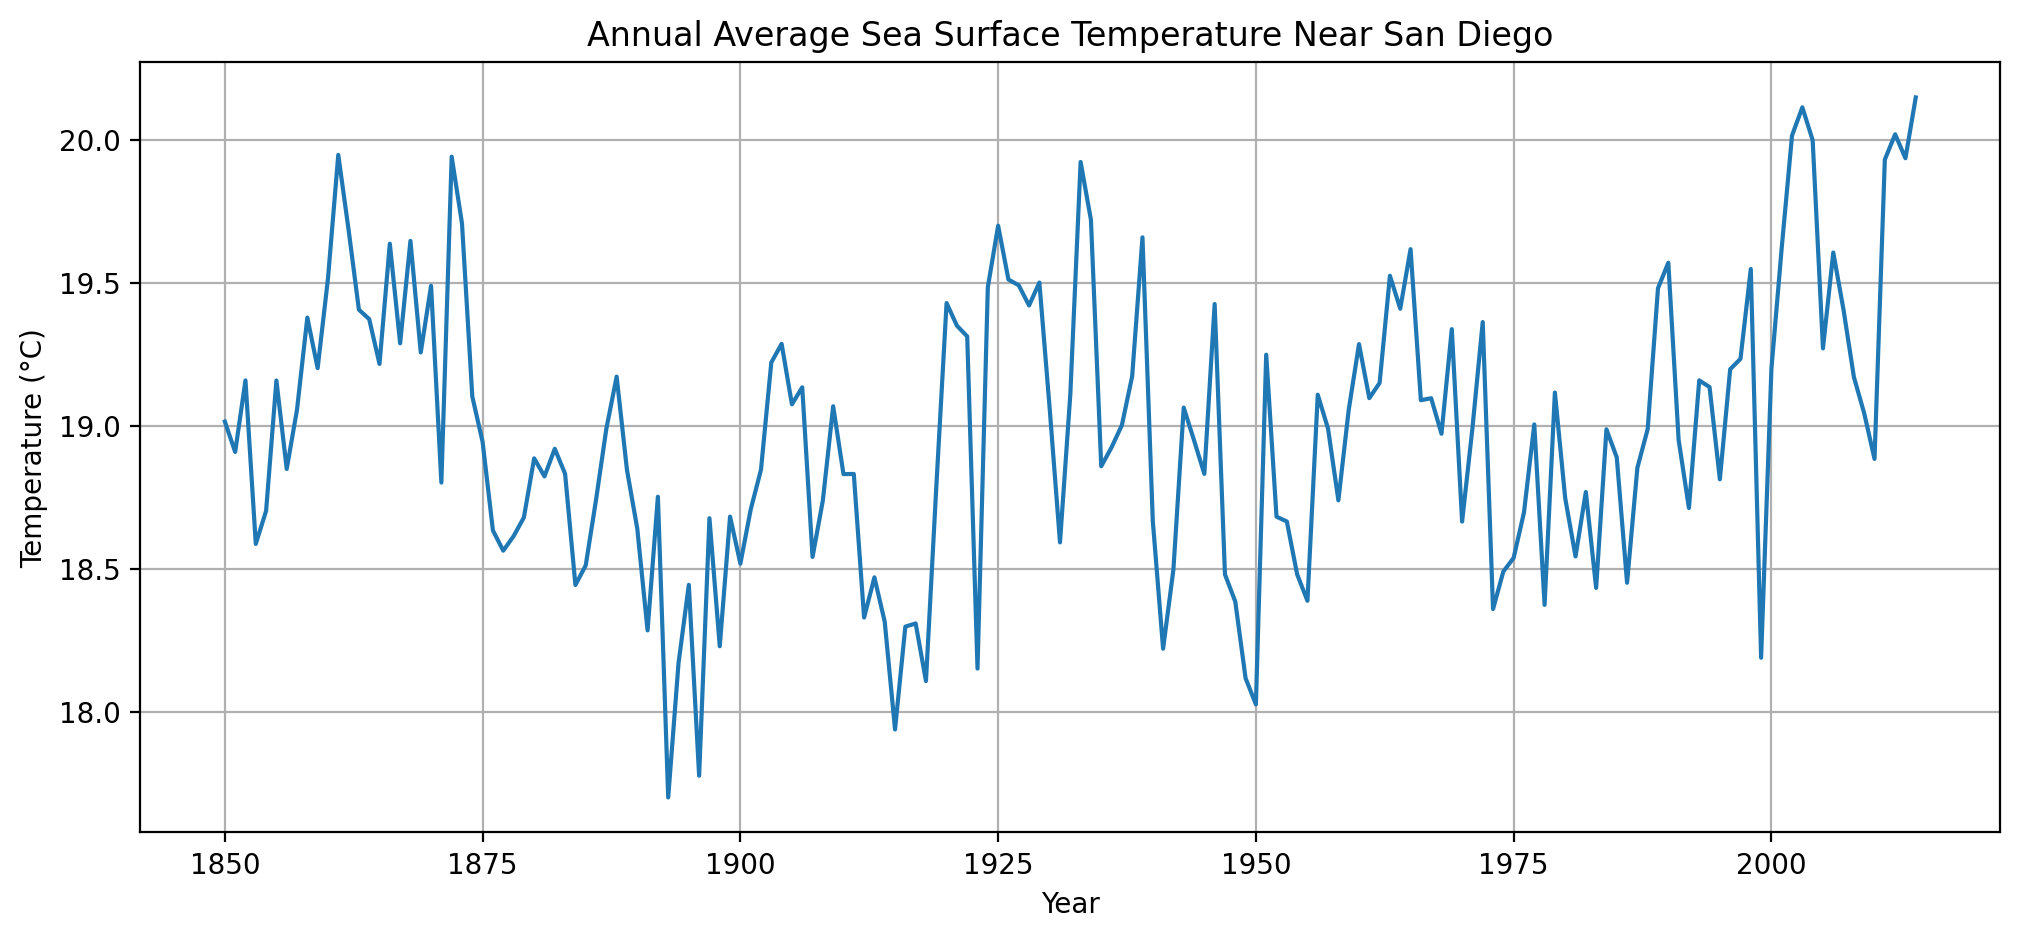

In [10]:
annual_sst = sst_location.groupby("time.year").mean()

plt.figure(figsize=(12, 5))
plt.plot(annual_sst.year.values, annual_sst.values)

plt.title("Annual Average Sea Surface Temperature Near San Diego")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.savefig('sdtemp.png')
plt.show()


In [12]:
print(catalog.columns)
print(catalog["variable_id"].unique())

NameError: name 'catalog' is not defined